# Final Project: Chlorophyll-a in Blue Mesa Reservoir

### CS 82A — Data Science
### Svetlana Babaeva

## Research Question
### How does chlorophyll-a concentration vary among the three basins of Blue Mesa Reservoir, Colorado, from 2016 to 2023?

## 1. Dataset and Source

- Dataset: Remotely sensed and in-situ chlorophyll-a and temperature data from Blue Mesa Reservoir, Colorado.
- Source: U.S. Geological Survey (USGS).
- File: `chl_rs_values.csv`
- Period: 2016–2023.
- DOI: https://doi.org/10.5066/P9XULQAS
- License: CC0 1.0 Universal (Public Domain).

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load the Dataset

In [2]:
df = pd.read_csv("chl_rs_values.csv")

df.head()

,date,basin,median_chl,stdev_chl,p90,max_chl,n,lowstdev,highstdev
0,6/26/2016,Iola,2.397146,2.090034,6.125180,33.563732,80178,0.307113,4.487180
1,6/26/2016,Cebolla,1.950797,1.653066,4.761046,29.655293,88057,0.297732,3.603863
2,6/26/2016,Sapinero,1.772666,1.181827,2.298890,30.896698,127550,0.590838,2.954493
3,7/16/2016,Iola,2.983919,2.365944,7.131243,31.256124,68031,0.617976,5.349863
4,7/16/2016,Cebolla,2.377821,1.813367,6.134974,25.234962,50992,0.564453,4.191188


The first five rows show chlorophyll-a statistics for the three basins: Iola, Cebolla, and Sapinero. Each row represents one basin on a specific date.


## 3. Data Inspection and Cleaning

### 3.1 Check the Dataset Structure


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

Dataset shape: (497, 9)

Column names:
Index(['date', 'basin', 'median_chl', 'stdev_chl', 'p90', 'max_chl', 'n',
       'lowstdev', 'highstdev'],
      dtype='str')

Data types:
date              str
basin             str
median_chl    float64
stdev_chl     float64
p90           float64
max_chl       float64
n               int64
lowstdev      float64
highstdev     float64
dtype: object


The dataset contains 497 rows and 9 columns. Most columns are numeric, while date and basin are stored as strings. The date column needs to be converted to datetime for further analysis.

### 3.2 Check Missing Values and Duplicates


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
date          0
basin         0
median_chl    0
stdev_chl     0
p90           0
max_chl       0
n             0
lowstdev      0
highstdev     0
dtype: int64

Duplicate rows: 0


No missing values or duplicate rows were found. All 497 rows were retained. Further cleaning will include checking data types, consistency, and possible invalid values.

### 3.3 Convert Dates

In [5]:
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

print("Date data type:", df["date"].dtype)
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())

Date data type: datetime64[us]
Earliest date: 2016-06-26 00:00:00
Latest date: 2023-10-28 00:00:00


### 3.4 Check Basin Names

In [6]:
print("Basin names:", df["basin"].unique())

print("\nRecords per basin:")
print(df["basin"].value_counts())

Basin names: <StringArray>
['Iola', 'Cebolla', 'Sapinero']
Length: 3, dtype: str

Records per basin:
basin
Sapinero    167
Iola        165
Cebolla     165
Name: count, dtype: int64


The dataset contains three basins: Iola (165 records), Cebolla (165), and Sapinero (167). All basin names are consistent

### 3.5 Check Duplicate Date–Basin Combinations


In [7]:
duplicates = df.duplicated(subset=["date", "basin"]).sum()

print("Duplicate date–basin combinations:", duplicates)

Duplicate date–basin combinations: 0


### 3.6 Check Numeric Values

In [8]:
df.describe()

,date,median_chl,stdev_chl,p90,max_chl,n,lowstdev,highstdev
count,497,497.000000,497.000000,497.000000,497.000000,497.000000,497.000000,497.000000
mean,2020-09-01 19:45:01.810865,4.760117,2.833341,8.246617,31.203348,70045.134809,1.926775,7.593458
min,2016-06-26 00:00:00,1.600902,0.302377,1.895433,3.531711,48.000000,-3.529231,2.532427
25%,2019-06-01 00:00:00,2.228855,1.604709,4.596524,29.655293,47500.000000,0.332748,3.935482
50%,2020-08-09 00:00:00,2.973729,2.099063,5.663348,31.665152,72184.000000,0.989721,4.997626
75%,2022-07-15 00:00:00,5.224988,3.108435,7.669678,33.524830,91725.000000,2.133223,8.061004
max,2023-10-28 00:00:00,27.132731,12.057987,36.727977,50.217857,136077.000000,23.248454,37.262765
std,NaN,4.633627,1.974314,6.880808,5.046492,30867.524317,3.421211,6.247571


All 497 records contain numeric values. Chlorophyll-a median concentrations range from 1.60 to 27.13 µg/L. Some calculated lower bounds (lowstdev) are negative and require further examination.

### 3.7 Check Negative Lower Bounds


In [9]:
print("Negative lower bounds:", (df["lowstdev"] < 0).sum())

print("Lower bounds match median minus standard deviation:",
      np.allclose(df["lowstdev"], df["median_chl"] - df["stdev_chl"]))

Negative lower bounds: 64
Lower bounds match median minus standard deviation: False


In [10]:
difference = df["lowstdev"] - (df["median_chl"] - df["stdev_chl"])

print("Maximum absolute difference:", difference.abs().max())
print("Rows with differences:", (~np.isclose(df["lowstdev"], df["median_chl"] - df["stdev_chl"])).sum())

Maximum absolute difference: 1.1999999813770544e-08
Rows with differences: 1


Chlorophyll-a concentration cannot physically be negative. The 64 negative lower bounds are results of a calculation (median minus standard deviation), not actual concentrations. One row has a very small rounding difference. I will keep all 497 rows.


### 3.8 Check Data Coverage by Year and Basin

In [11]:
df["year"] = df["date"].dt.year

coverage = df.groupby(["year", "basin"]).size().unstack(fill_value=0)

coverage

basin,Cebolla,Iola,Sapinero
year,,,
2016,6,6,6
2017,12,12,12
2018,20,20,20
2019,29,29,30
2020,30,30,30
2021,22,22,22
2022,20,19,20
2023,26,27,27


All three basins have data from 2016 to 2023. The number of records varies by year, but the three basins have similar coverage within each year. We will consider these differences when comparing chlorophyll-a concentrations over time.

### 3.9 Check Seasonal Coverage

In [12]:
df["month"] = df["date"].dt.month

print("Records by month:")
print(df["month"].value_counts().sort_index())

Records by month:
month
5      59
6      60
7     111
8      96
9      90
10     81
Name: count, dtype: int64


The dataset covers May through October, with more records in summer than in spring or fall. Our seasonal analysis will be limited to these six months.

### 3.10  Cleaning Log
Before analyzing the data, I checked for missing values, duplicate records, incorrect data types, and unusual numbers.
No missing values or duplicate records were found. The basin names were consistent. The dates were stored as text, so I converted them to datetime format to analyze the data by year and month.
I found 64 negative values in the lowstdev column. Chlorophyll-a concentrations cannot physically be negative, but these values are calculated by subtracting the standard deviation from the median. They do not represent actual negative concentrations, so I kept them.
The dataset covers 2016–2023, but only May through October. Some years have more records than others, which I will consider when comparing the results.

## 4. Exploratory Data Analysis and Statistics

### 4.1 Chlorophyll-a Statistics by Basin


In [13]:
basin_stats = df.groupby("basin")["median_chl"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

basin_stats.round(2)

,count,mean,median,std,min,max
basin,,,,,,
Cebolla,165,3.77,2.71,2.99,1.64,21.22
Iola,165,7.49,5.27,6.26,1.98,27.13
Sapinero,167,3.03,2.32,2.28,1.60,21.60


Iola has the highest mean chlorophyll-a concentration (7.49 µg/L), followed by Cebolla (3.77 µg/L) and Sapinero (3.03 µg/L). Iola also has the greatest variation in concentrations.

### 4.2 Annual Variation

In [14]:
annual_stats = df.groupby(["year", "basin"])["median_chl"].mean().unstack()

annual_stats.round(2)

basin,Cebolla,Iola,Sapinero
year,,,
2016,2.20,3.03,2.08
2017,2.38,2.84,2.09
2018,2.42,5.50,1.96
2019,4.92,7.97,4.29
2020,2.91,6.48,2.31
2021,5.61,10.56,2.81
2022,4.39,14.28,4.06
2023,3.51,5.38,3.28


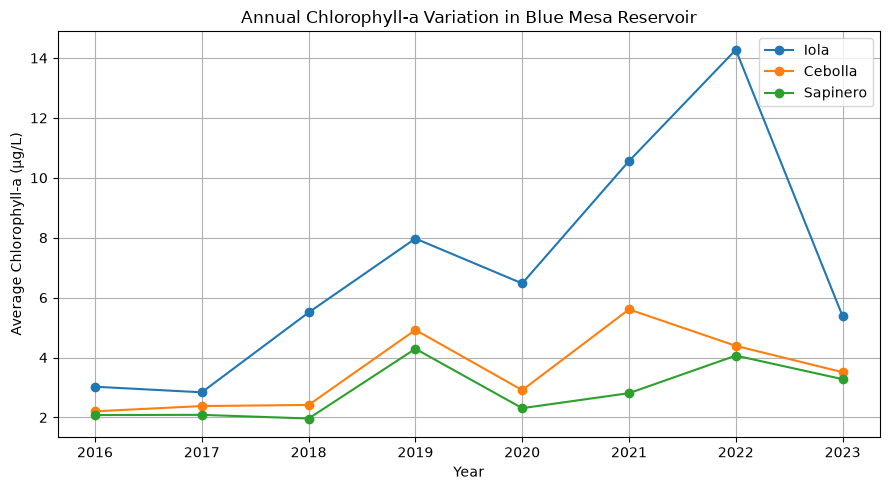

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(annual_stats.index, annual_stats["Iola"], marker="o", label="Iola")
plt.plot(annual_stats.index, annual_stats["Cebolla"], marker="o", label="Cebolla")
plt.plot(annual_stats.index, annual_stats["Sapinero"], marker="o", label="Sapinero")

plt.title("Annual Chlorophyll-a Variation in Blue Mesa Reservoir")
plt.xlabel("Year")
plt.ylabel("Average Chlorophyll-a (µg/L)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Fig.1 Iola had the highest average chlorophyll-a concentration in every year. Its highest annual average was 14.28 µg/L in 2022. Concentrations varied from year to year in all three basins, without a consistent increase or decrease.

### 4.3 Seasonal Variation


In [16]:
monthly_stats = df.groupby(["month", "basin"])["median_chl"].mean().unstack()
monthly_stats.round(2)

basin,Cebolla,Iola,Sapinero
month,,,
5,3.85,6.41,5.16
6,2.70,3.66,2.53
7,2.38,4.64,2.13
8,4.24,9.51,2.48
9,5.10,12.23,3.42
10,4.40,7.36,3.23


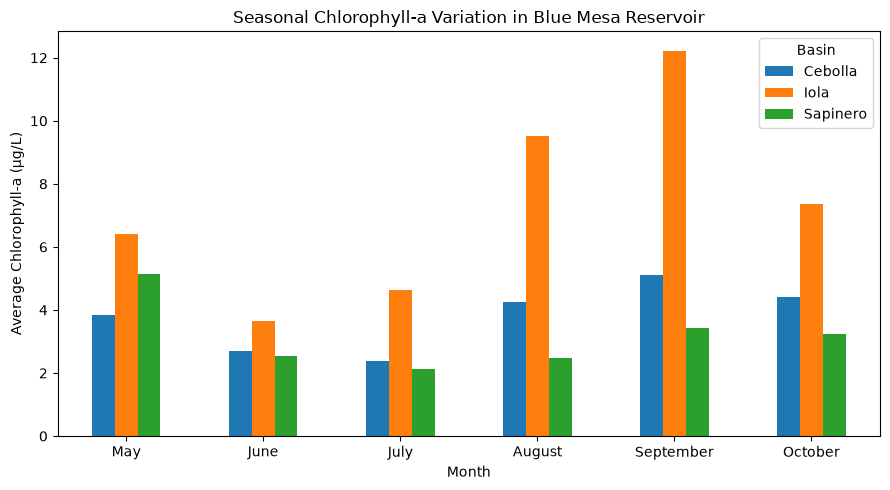

In [17]:
monthly_stats.plot(kind="bar", figsize=(9, 5))

plt.title("Seasonal Chlorophyll-a Variation in Blue Mesa Reservoir")
plt.xlabel("Month")
plt.ylabel("Average Chlorophyll-a (µg/L)")
plt.xticks(range(6), ["May", "June", "July", "August", "September", "October"], rotation=0)
plt.legend(title="Basin")
plt.tight_layout()
plt.show()

Fig.2 Iola had the highest average chlorophyll-a concentration in every month, with the highest value in September (12.23 µg/L). Cebolla also reached its highest average in September, while Sapinero had its highest average in May.

### 4.4 Basin Comparison — Boxplot

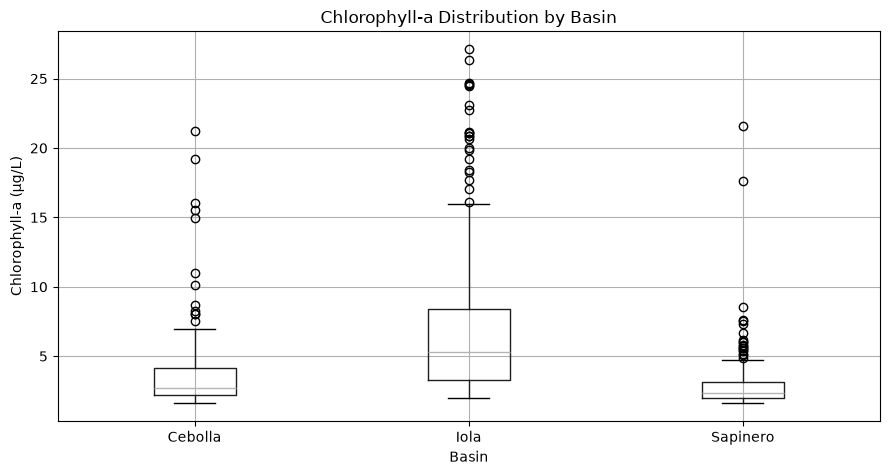

In [18]:
df.boxplot(column="median_chl", by="basin", figsize=(9, 5))

plt.title("Chlorophyll-a Distribution by Basin")
plt.suptitle("")
plt.xlabel("Basin")
plt.ylabel("Chlorophyll-a (µg/L)")
plt.tight_layout()
plt.show()

Fig. 3 Iola had the highest median chlorophyll-a concentration (5.27 µg/L) and the greatest variation. Cebolla and Sapinero had lower median concentrations (2.71 and 2.32 µg/L). All three basins had some unusually high values.

## 5.  Results and Limitations

### Results
This  analysis showed differences in chlorophyll-a concentrations among the three basins of Blue Mesa Reservoir from 2016 to 2023.

Iola had the highest average chlorophyll-a concentration (7.49 µg/L), followed by Cebolla (3.77 µg/L) and Sapinero (3.03 µg/L). Iola also had the highest median concentration (5.27 µg/L), compared with Cebolla (2.71 µg/L) and Sapinero (2.32 µg/L).

The annual analysis showed that Iola had the highest average concentration in every year from 2016 to 2023. Its highest annual average was recorded in 2022 (14.28 µg/L). Chlorophyll-a concentrations varied between years in all three basins, without a consistent increase or decrease.

The monthly analysis showed differences between May and October. Iola had the highest average concentration in every month, reaching 12.23 µg/L in September. Cebolla also reached its highest monthly average in September (5.10 µg/L), while Sapinero had its highest average in May (5.16 µg/L).

The boxplot showed that Iola had the greatest variation in chlorophyll-a concentrations. All three basins also had some unusually high values.

Overall, Iola had higher chlorophyll-a concentrations and greater variability than Cebolla and Sapinero during the period studied.

### Limitations
The dataset includes observations from May through October, so this analysis focuses on seasonal patterns during this period. Winter conditions were not included in the available data.

The number of observations differs between years, which may affect comparisons of annual averages. Differences in the months sampled each year may also influence these comparisons.

The chlorophyll-a concentrations are based on remotely sensed estimates rather than direct measurements of individual water samples. These estimates may contain uncertainty. Moreover, our analysis does not determine the environmental factors (such as temperature, landscape characteristics, and other conditions) responsible for the observed differences in chlorophyll-a concentrations.

## 6. Conclusion
Our analysis showed that chlorophyll-a concentrations varied among the three basins of Blue Mesa Reservoir from 2016 to 2023. Iola generally had higher concentrations and greater variation than Cebolla and Sapinero. Concentrations also changed between years and months. These results show differences in chlorophyll-a concentrations across the reservoir, but further research would be needed to understand their causes.

## 7. Reproducibility and AI Use

7. Reproducibility and AI Use

I used JupyterLab and Python to complete this project. The notebook and dataset are provided so the analysis can be repeated. 
I used AI to help with the syntax. I checked the results in JupyterLab using the original data.